In [126]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [127]:
df = pd.read_csv('../data/raw/netflix_customer_churn.csv')

df.head(10)

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action
5,d8079475-5be7-47e9-8782-ceb7ff61395e,58,Female,Standard,13.80,26,Oceania,Mobile,13.99,0,Debit Card,3,0.51,Action
6,8e63450a-13d6-4e83-bbb5-6aebde9152cb,48,Other,Basic,13.83,20,Asia,TV,8.99,0,Gift Card,5,0.66,Romance
7,02387681-8c42-462a-807a-de0168c73b38,51,Male,Basic,14.30,56,Europe,Mobile,8.99,1,Gift Card,1,0.25,Action
8,0bcaad0c-545c-4ee1-85a6-75e165f39361,45,Other,Basic,9.98,10,Asia,Mobile,8.99,0,PayPal,3,0.91,Romance
9,eae6439e-8cdf-4258-ab49-c493925b927a,32,Other,Premium,2.22,34,Europe,TV,17.99,1,Debit Card,1,0.06,Drama


In [128]:
df.shape

(5000, 14)

In [129]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   str    
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   str    
 3   subscription_type       5000 non-null   str    
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   str    
 7   device                  5000 non-null   str    
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   int64  
 10  payment_method          5000 non-null   str    
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000 non-null   str    
dtypes: float64(3), int64(4), str(7)
memory usage: 547.0

In [130]:
df.describe()

,age,watch_hours,last_login_days,monthly_fee,churned,number_of_profiles,avg_watch_time_per_day
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,43.847400,11.649450,30.089800,13.683400,0.503000,3.024400,0.874800
std,15.501128,12.014654,17.536078,3.692062,0.500041,1.415841,2.619824
min,18.000000,0.010000,0.000000,8.990000,0.000000,1.000000,0.000000
25%,30.000000,3.337500,15.000000,8.990000,0.000000,2.000000,0.110000
50%,44.000000,8.000000,30.000000,13.990000,1.000000,3.000000,0.290000
75%,58.000000,16.030000,45.000000,17.990000,1.000000,4.000000,0.720000
max,70.000000,110.400000,60.000000,17.990000,1.000000,5.000000,98.420000


In [131]:
df.isnull().sum()

customer_id               0
age                       0
gender                    0
subscription_type         0
watch_hours               0
last_login_days           0
region                    0
device                    0
monthly_fee               0
churned                   0
payment_method            0
number_of_profiles        0
avg_watch_time_per_day    0
favorite_genre            0
dtype: int64

In [132]:
df.duplicated().sum()

np.int64(0)

In [133]:
df['churned'].value_counts()

churned
1    2515
0    2485
Name: count, dtype: int64

In [134]:
active = df[df['churned'] == 0].value_counts().sum()
churned = df[df['churned'] == 1].value_counts().sum()

print(f'Active subscribers: {active}, churned subscribers: {churned}')

Active subscribers: 2485, churned subscribers: 2515


In [135]:
percent_active = active / (active + churned) * 100
percent_churned = churned / (active + churned) * 100
print(f'Percentage of active subscribers: {percent_active:.2f}%, Percentage of churned subscribers: {percent_churned:.2f}%')

Percentage of active subscribers: 49.70%, Percentage of churned subscribers: 50.30%


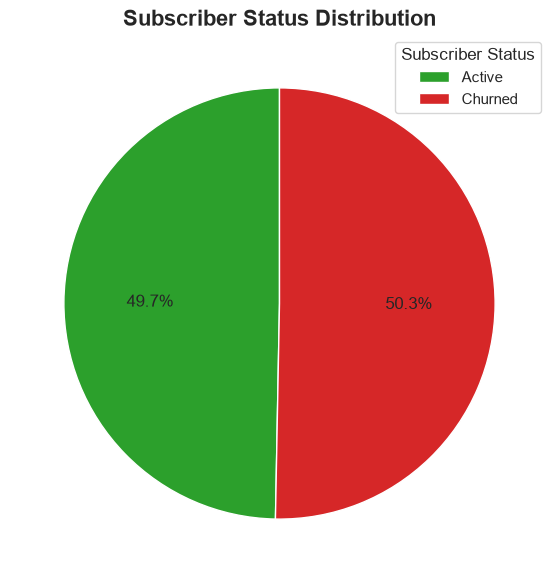

In [136]:
plt.figure(figsize=(9, 7))
plt.pie([active, churned], 
    autopct='%1.1f%%', 
    startangle=90,
    colors = ['#2ca02c', '#d62728',])

plt.title('Subscriber Status Distribution',
    fontsize=16, 
    fontweight='bold'
)

plt.legend(title='Subscriber Status', 
    labels=['Active', 'Churned'], 
    loc='upper right'
)

plt.savefig('../reports/charts/subscriber_status_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

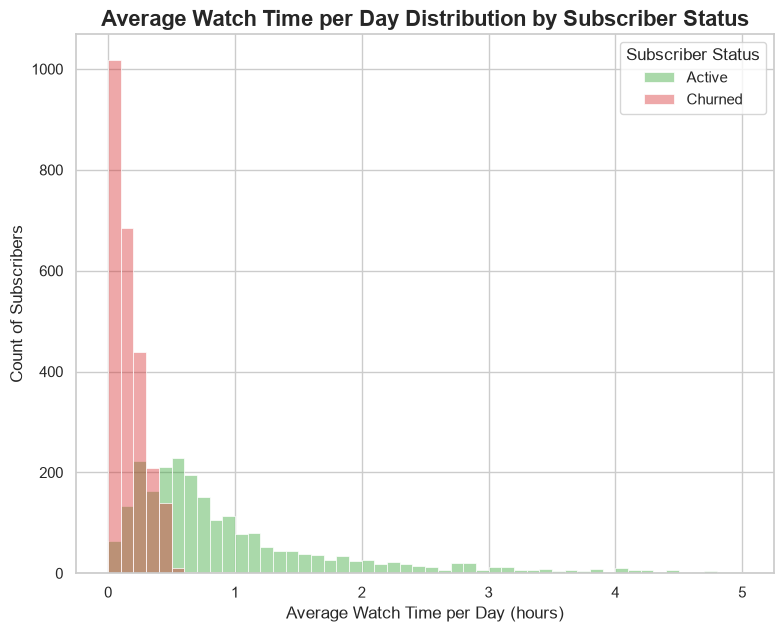

In [137]:
df['churn_rate'] = df['churned'].map({0: 'Active', 1: 'Churned'})

plt.figure(figsize=(9, 7))

sns.set_theme(style = "whitegrid")

sns.histplot(data=df, 
    x='avg_watch_time_per_day', 
    hue='churn_rate',
    binwidth=0.1,
    palette = ['#d62728', '#2ca02c',],
    alpha = 0.4,
    edgecolor = 'white',
    linewidth = 0.5,
    binrange=(0, 5)
)

plt.xticks(range(0, 6, 1))

plt.title('Average Watch Time per Day Distribution by Subscriber Status',
    fontsize=16, 
    fontweight='bold'
)

plt.legend(title='Subscriber Status', 
    labels=['Active', 'Churned'], 
    loc='upper right'
)

plt.xlabel('Average Watch Time per Day (hours)')
plt.ylabel('Count of Subscribers')

plt.savefig('../reports/charts/avg_watch_time_per_day.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

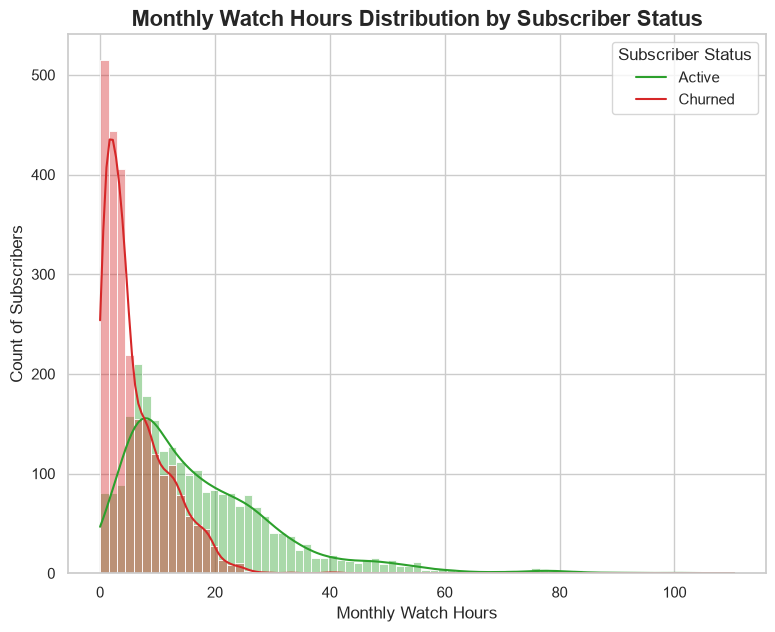

In [143]:
df['churn_rate'] = df['churned'].map({0: 'Active', 1: 'Churned'})

plt.figure(figsize=(9, 7))

sns.set_theme(style = "whitegrid")

sns.histplot(data=df, 
    x='watch_hours', 
    hue='churn_rate',
    kde = True,
    palette = ['#d62728', '#2ca02c',],
    alpha = 0.4,
)

plt.title('Monthly Watch Hours Distribution by Subscriber Status',
    fontsize=16, 
    fontweight='bold'
)

plt.legend(title='Subscriber Status', 
    labels=['Active', 'Churned'], 
    loc='upper right'
)

plt.xlabel('Monthly Watch Hours')
plt.ylabel('Count of Subscribers')

plt.savefig('../reports/charts/watch_hours_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

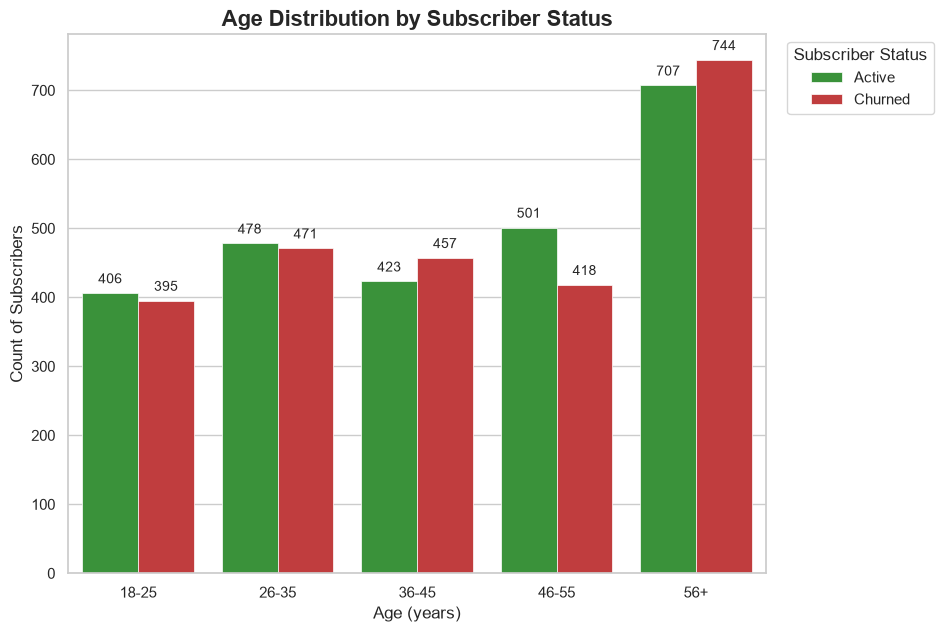

In [138]:
df['churn_rate'] = df['churned'].map({0: 'Active', 1: 'Churned'})

bins = [17, 25, 35, 45, 55, 100]
labels = ['18-25', '26-35', '36-45', '46-55', '56+']
df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels)

plt.figure(figsize=(9, 7))

sns.set_theme(style = "whitegrid")

ax = sns.countplot(
    data=df, 
    x='age_group', 
    hue='churn_rate',
    palette=['#2ca02c', '#d62728'], 
    edgecolor='white',
    linewidth=0.5
)

for container in ax.containers:
    ax.bar_label(container, fontsize = 10, padding = 5)

plt.title('Age Distribution by Subscriber Status',
    fontsize=16, 
    fontweight='bold'
)

plt.legend(title='Subscriber Status', 
    labels=['Active', 'Churned'], 
    loc='upper left',
    bbox_to_anchor=(1.02, 1),
    frameon=True
)

plt.xlabel('Age (years)')
plt.ylabel('Count of Subscribers')

plt.savefig('../reports/charts/age_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

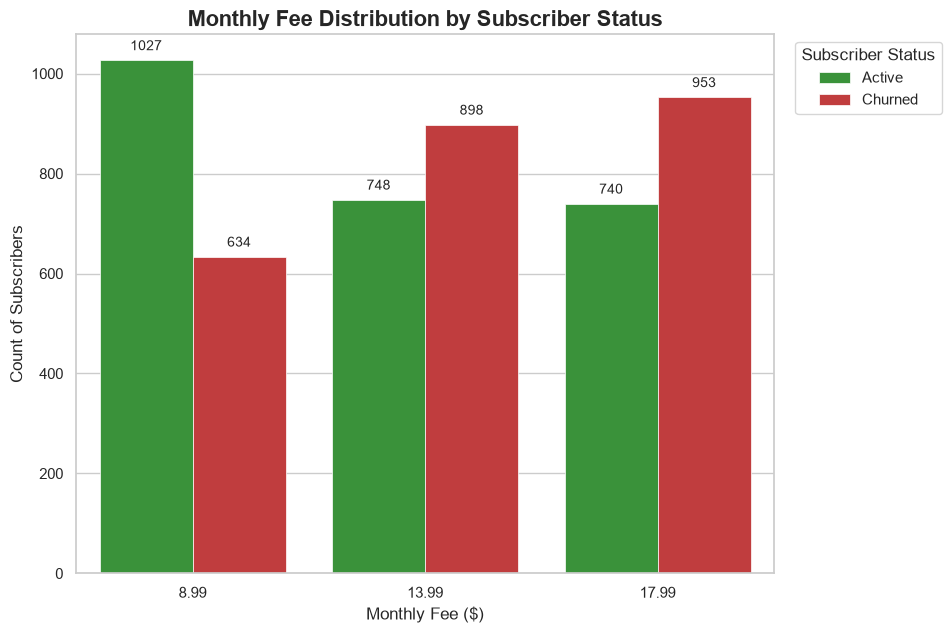

In [146]:
df['churn_rate'] = df['churned'].map({0: 'Active', 1: 'Churned'})

plt.figure(figsize=(9, 7))

sns.set_theme(style = "whitegrid")

ax = sns.countplot(
    data=df, 
    x='monthly_fee', 
    hue='churn_rate',
    palette=['#2ca02c', '#d62728'], 
    edgecolor='white',
    linewidth=0.5
)

for container in ax.containers:
    ax.bar_label(container, fontsize = 10, padding = 5)

plt.title('Monthly Fee Distribution by Subscriber Status',
    fontsize=16, 
    fontweight='bold'
)

plt.legend(title='Subscriber Status', 
    labels=['Active', 'Churned'], 
    loc='upper left',
    bbox_to_anchor=(1.02, 1),
    frameon=True
)

plt.xlabel('Monthly Fee ($)')
plt.ylabel('Count of Subscribers')

plt.savefig('../reports/charts/monthly_fee_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


C:\Users\User\AppData\Local\Temp\ipykernel_24544\301477484.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


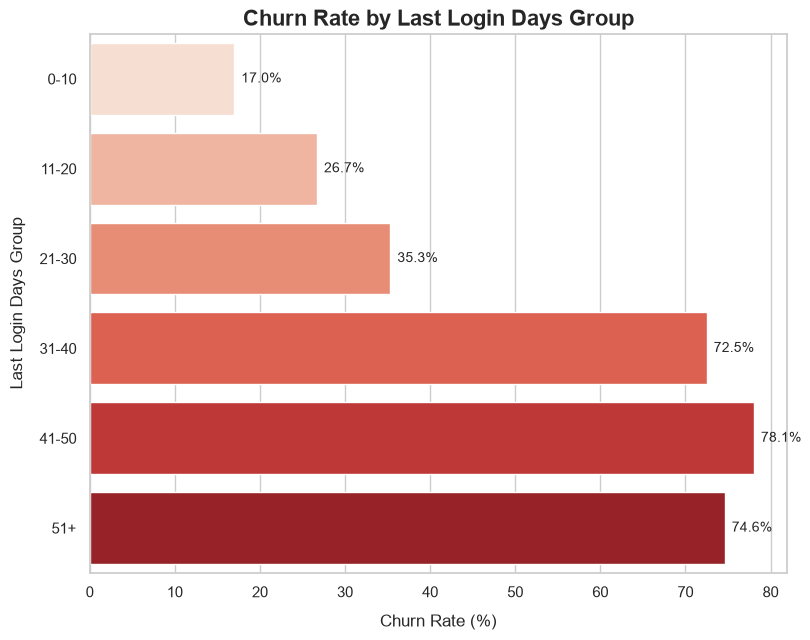

In [199]:
plt.figure(figsize=(9, 7))

sns.set_theme(style="whitegrid")

days_bins = [-1, 10, 20, 30, 40, 50, 60]
labels = ['0-10', '11-20', '21-30', '31-40', '41-50', '51+']

df['login_days_group'] = pd.cut(df['last_login_days'], bins=days_bins, labels=labels)

churn_rates = df.groupby('login_days_group')['churned'].mean().reset_index()

churn_rates['churn_percentage'] = churn_rates['churned'] * 100


ax = sns.barplot(
    x='churn_percentage', 
    y='login_days_group', 
    data=churn_rates, 
    palette='Reds',
    legend = False
)

plt.title('Churn Rate by Last Login Days Group',
    fontsize=16, 
    fontweight='bold'
)

for container in ax.containers:
    values = container.datavalues
    labels = [f'{v:.1f}%' for v in values]
    ax.bar_label(container, labels = labels, fontsize = 10, padding = 5)

plt.xlabel('Churn Rate (%)', labelpad=10)
plt.ylabel('Last Login Days Group', labelpad=10)


plt.savefig('../reports/charts/churn_rate_by_last_login_days.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

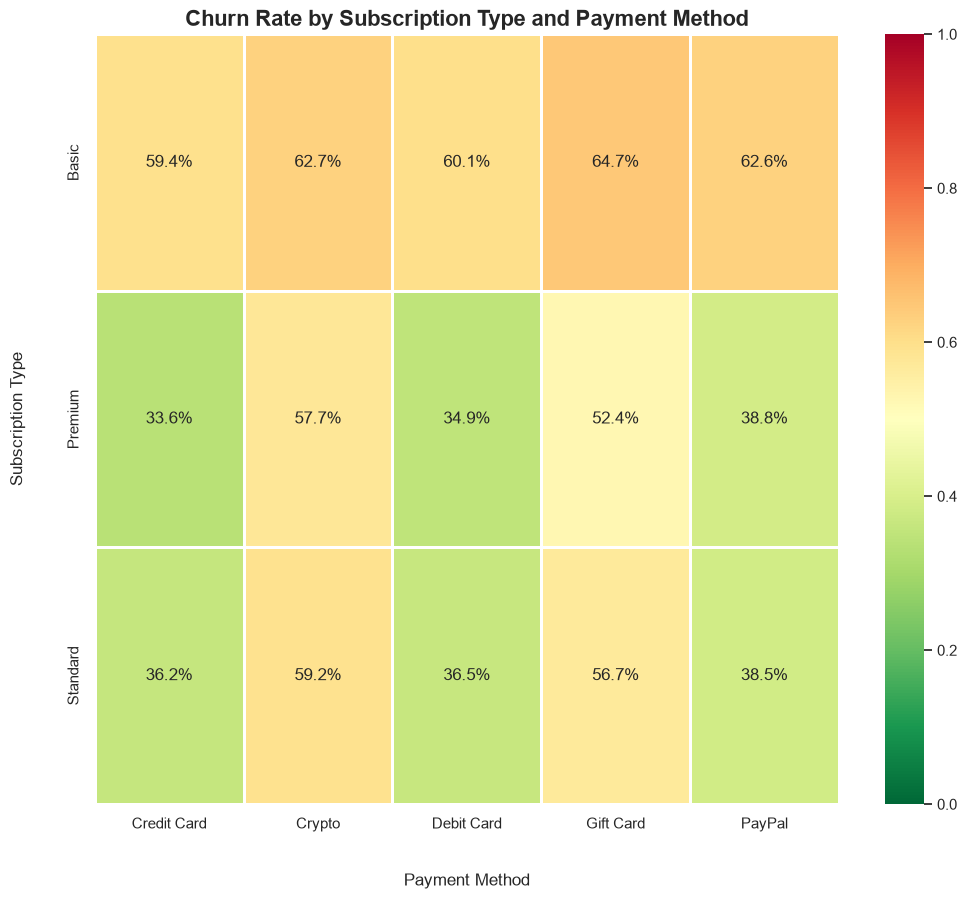

In [165]:
sns.set_theme(style = "whitegrid")

pivot = df.pivot_table(
    index='subscription_type',
    columns='payment_method',
    values='churned',
    aggfunc='mean'
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    pivot,
    annot=True,
    fmt='.1%',
    cmap='RdYlGn_r',
    linewidths=2,
    vmin=0,
    vmax=1
)

plt.title('Churn Rate by Subscription Type and Payment Method',
    fontsize=16, 
    fontweight='bold'
)

plt.xlabel('Payment Method',
    fontsize=12,
    labelpad=30
)
plt.ylabel('Subscription Type',
    fontsize=12,
    labelpad=30
)

plt.savefig('../reports/charts/churn_rate_by_subscription_and_payment.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

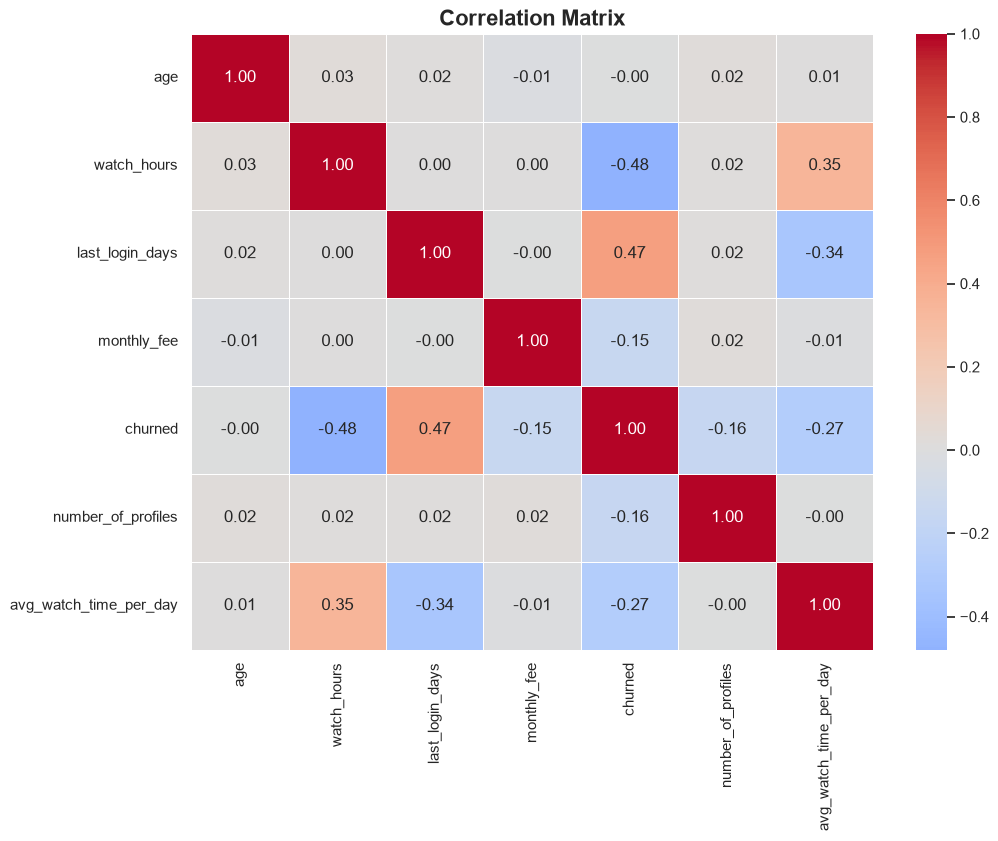

In [166]:
plt.figure(figsize=(11, 8))

sns.set_theme(style = "whitegrid")

numeric_df = df.select_dtypes(include='number')

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title('Correlation Matrix',
    fontsize=16, 
    fontweight='bold'
)

plt.savefig('../reports/charts/correlation_matrix.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()